# Зертханалық жұмыс №1

## 1. Ортаны баптау
Қажетті кітапханаларды (`OpenCV`, `NumPy`, `PyTorch`) 

In [12]:
import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
import os

print("OpenCV нұсқасы:", cv2.__version__)
print("NumPy нұсқасы:", np.__version__)
print("PyTorch нұсқасы:", torch.__version__)
print("CUDA қолжетімді ме:", torch.cuda.is_available())
print("MPS (Apple GPU) қолжетімді ме:", torch.backends.mps.is_available())


OpenCV нұсқасы: 5.0.0
NumPy нұсқасы: 2.5.3
PyTorch нұсқасы: 2.14.0
CUDA қолжетімді ме: False
MPS (Apple GPU) қолжетімді ме: True


## 2. Өз фотоны оқу
Фотоны `cv2.imread()` арқылы оқып, оның өлшемін (shape), деректер типін (dtype) және орташа жарықтығын (grayscale бойынша орташа пиксель мәні) есептеу керек.

Кескін өлшемі (ені x биіктігі): 234 x 320
Арналар саны: 3
Деректер типі (dtype): uint8
Массив пішіні (shape): (320, 234, 3)
Орташа жарықтық: 75.09


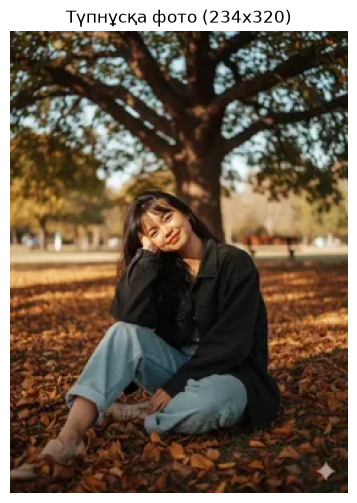

In [13]:
IMAGE_PATH = "images/photo.webp"
OUTPUT_DIR = "output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

img = cv2.imread(IMAGE_PATH)

if img is None:
    raise FileNotFoundError(f"Кескінді оқу мүмкін болмады: {IMAGE_PATH}")

height, width, channels = img.shape
gray_for_brightness = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
mean_brightness = gray_for_brightness.mean()

print(f"Кескін өлшемі (ені x биіктігі): {width} x {height}")
print(f"Арналар саны: {channels}")
print(f"Деректер типі (dtype): {img.dtype}")
print(f"Массив пішіні (shape): {img.shape}")
print(f"Орташа жарықтық: {mean_brightness:.2f}")

plt.figure(figsize=(5, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"Түпнұсқа фото ({width}x{height})")
plt.axis("off")
plt.savefig(os.path.join(OUTPUT_DIR, "01_original.png"), bbox_inches="tight", dpi=120)
plt.show()


## 3. Сұр түске айналдыру және PNG/JPEG форматында сақтау
Кескінді `cv2.cvtColor()` арқылы сұр түске (grayscale) айналдырып, нәтижені PNG форматында, сонымен қатар JPEG форматында әр түрлі сапада (50 және 90) сақтау керек.

output/gray_image.png -> 54.4 KB
output/gray_image_q50.jpg -> 11.9 KB
output/gray_image_q90.jpg -> 27.5 KB


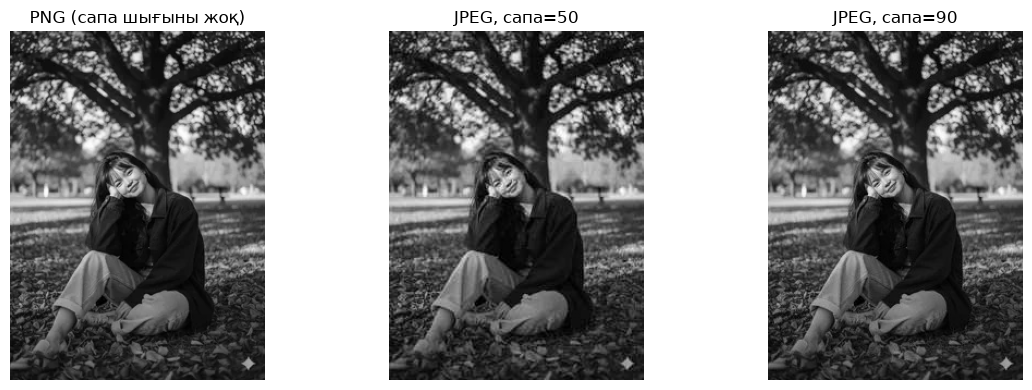

In [14]:
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

png_path = os.path.join(OUTPUT_DIR, "gray_image.png")
jpeg_q50_path = os.path.join(OUTPUT_DIR, "gray_image_q50.jpg")
jpeg_q90_path = os.path.join(OUTPUT_DIR, "gray_image_q90.jpg")

cv2.imwrite(png_path, gray)
cv2.imwrite(jpeg_q50_path, gray, [cv2.IMWRITE_JPEG_QUALITY, 50])
cv2.imwrite(jpeg_q90_path, gray, [cv2.IMWRITE_JPEG_QUALITY, 90])

for path in [png_path, jpeg_q50_path, jpeg_q90_path]:
    size_kb = os.path.getsize(path) / 1024
    print(f"{path} -> {size_kb:.1f} KB")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
titles = ["PNG (сапа шығыны жоқ)", "JPEG, сапа=50", "JPEG, сапа=90"]
paths = [png_path, jpeg_q50_path, jpeg_q90_path]
for ax, title, path in zip(axes, titles, paths):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "02_gray_formats.png"), bbox_inches="tight", dpi=120)
plt.show()


## 4. Кескінге рамка мен мәтін салу, аймақты қиып алу


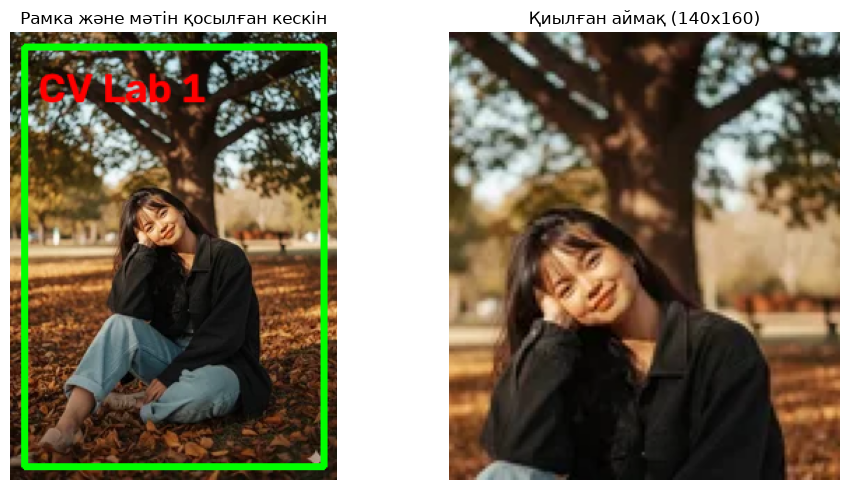

In [15]:
img_annotated = img.copy()
h, w = img_annotated.shape[:2]

border = 10
cv2.rectangle(img_annotated, (border, border), (w - border, h - border), (0, 255, 0), 4)

cv2.putText(
    img_annotated,
    "CV Lab 1",
    (border + 10, border + 40),
    cv2.FONT_HERSHEY_SIMPLEX,
    1.0,
    (0, 0, 255),
    2,
    cv2.LINE_AA,
)

annotated_path = os.path.join(OUTPUT_DIR, "annotated_image.png")
cv2.imwrite(annotated_path, img_annotated)

x1, y1, x2, y2 = int(w * 0.25), int(h * 0.15), int(w * 0.85), int(h * 0.65)
cropped = img[y1:y2, x1:x2]
cropped_path = os.path.join(OUTPUT_DIR, "cropped_region.png")
cv2.imwrite(cropped_path, cropped)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(cv2.cvtColor(img_annotated, cv2.COLOR_BGR2RGB))
axes[0].set_title("Рамка және мәтін қосылған кескін")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Қиылған аймақ ({cropped.shape[1]}x{cropped.shape[0]})")
axes[1].axis("off")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "03_annotated_and_crop.png"), bbox_inches="tight", dpi=120)
plt.show()


## 5. B, G, R арналарын matplotlib subplot арқылы көрсету


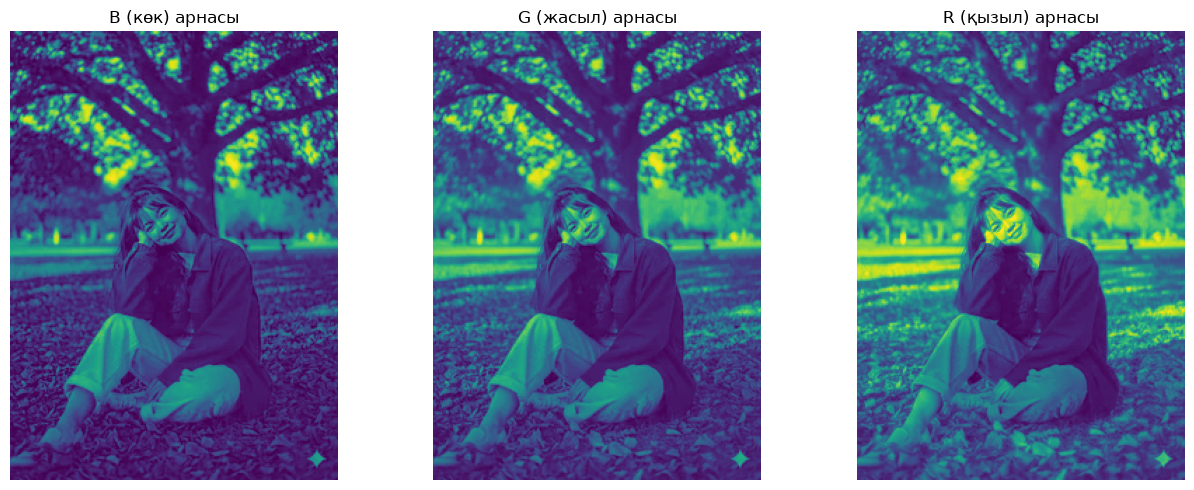

B арнасының орташа мәні: 53.11
G арнасының орташа мәні: 72.10
R арнасының орташа мәні: 89.39


In [17]:
b, g, r = cv2.split(img)

fig, axes = plt.subplots(1, 3, figsize=(13, 5))

axes[0].imshow(b)
axes[0].set_title("B (көк) арнасы")
axes[0].axis("off")

axes[1].imshow(g)
axes[1].set_title("G (жасыл) арнасы")
axes[1].axis("off")

axes[2].imshow(r)
axes[2].set_title("R (қызыл) арнасы")
axes[2].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "04_bgr_channels.png"), bbox_inches="tight", dpi=120)
plt.show()

print(f"B арнасының орташа мәні: {b.mean():.2f}")
print(f"G арнасының орташа мәні: {g.mean():.2f}")
print(f"R арнасының орташа мәні: {r.mean():.2f}")


## Қорытынды

Осы зертханалық жұмыс барысында OpenCV, NumPy және PyTorch кітапханалары орнатылып, олардың нұсқалары тексерілді. Жеке фотосурет оқылып, оның өлшемі, деректер типі және орташа жарықтығы есептелді. Кескін сұр түске түрлендіріліп, PNG (сапа шығынсыз) және JPEG (сапа=50 және сапа=90) форматтарында сақталды — нәтижесінде JPEG сапасы төмендеген сайын файл өлшемі кішірейетіні, бірақ артефактілер көбейетінін байқадык. Кескінге рамка мен мәтін қосып, оның бір аймағы қиып алдык. Соңында кескіннің B, G, R түс арналары бөлек-бөлек шығарылып, әрқайсысының жарықтық үлесі салыстырылды, бұл OpenCV-дегі түстердің BGR тәртібімен сақталатынын және әр арнаның сурет мазмұнына әр түрлі әсер ететінін көрсетті.